# Government hospital beds per 1,000 population

This notebook replaces raw state-level bed counts with a population-adjusted availability measure using the Central Bureau of Health Intelligence's National Health Profile 2023. Bed counts are as of 31 December 2022. The denominator is the Ministry of Health & Family Welfare's projected population as of 1 March 2021, reported in thousands. The approximately 21-month timing gap is disclosed; rates are indicative, not exact same-date ratios.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('../Dataset')
beds = pd.read_csv(DATA / 'state_government_hospital_beds_nhp2023_per_1000.csv')
beds['beds_per_1000_population_recalculated'] = beds['beds_total_nhp2023'] / beds['population_2021_projected_thousands']
beds['rate_difference'] = beds['beds_per_1000_population'] - beds['beds_per_1000_population_recalculated']
assert beds['rate_difference'].abs().max() < 0.00011
print('State/UT observations:', len(beds))
print('Bed count reference date:', beds['beds_reference_date'].unique())
print('Population reference date:', beds['population_reference_date'].unique())
beds.head()

State/UT observations: 36
Bed count reference date: <StringArray>
['2022-12-31']
Length: 1, dtype: str
Population reference date: <StringArray>
['2021-03-01']
Length: 1, dtype: str


,state_ut,beds_total_nhp2023,beds_reference_date,population_2021_projected_thousands,population_reference_date,beds_per_1000_population,beds_per_1000_population_recalculated,rate_difference
0,Andhra Pradesh,39852,2022-12-31,52787,2021-03-01,0.7550,0.754959,0.000041
1,Arunachal Pradesh,2663,2022-12-31,1533,2021-03-01,1.7371,1.737117,-0.000017
2,Assam,23185,2022-12-31,35043,2021-03-01,0.6616,0.661616,-0.000016
3,Bihar,26518,2022-12-31,123083,2021-03-01,0.2154,0.215448,-0.000048
4,Chhattisgarh,9610,2022-12-31,29493,2021-03-01,0.3258,0.325840,-0.000040


## 1. Compare availability across states and UTs

The numerator covers government hospitals operated by central, state and local government bodies, and excludes private-sector beds. Delhi and Chandigarh are included as urban-only observations in the NHP table. The combined Dadra & Nagar Haveli and Daman & Diu population is summed from the two separate 2021 projections to match the merged bed-count geography.

In [2]:
ranked = beds.sort_values('beds_per_1000_population', ascending=False).copy()
display(ranked[['state_ut','beds_total_nhp2023','population_2021_projected_thousands','beds_per_1000_population']].round(3))
print('Median beds per 1,000 population:', round(beds['beds_per_1000_population'].median(), 3))
print('Mean beds per 1,000 population:', round(beds['beds_per_1000_population'].mean(), 3))
state_row_sum = int(beds['beds_total_nhp2023'].sum())
published_india_total = 840455  # NHP-2023 Table 6.2.2 India row
print('Sum of 36 state/UT bed rows:', state_row_sum)
print('Published India aggregate bed count:', published_india_total)
print('State-row sum minus published India total:', state_row_sum - published_india_total)
print('The discrepancy equals the Andhra Pradesh row; no national aggregate rate is calculated from these inconsistent totals.')

,state_ut,beds_total_nhp2023,population_2021_projected_thousands,beds_per_1000_population
34,Lakshadweep,250,68,3.676
28,Andaman & Nicobar Islands,1409,400,3.522
29,Chandigarh,4035,1208,3.340
33,Ladakh,802,297,2.700
21,Sikkim,1810,677,2.674
8,Himachal Pradesh,16590,7394,2.244
5,Goa,3378,1559,2.167
35,Puducherry,3306,1571,2.104
1,Arunachal Pradesh,2663,1533,1.737
16,Mizoram,1985,1216,1.632


Median beds per 1,000 population: 0.949
Mean beds per 1,000 population: 1.285
Sum of 36 state/UT bed rows: 880307
Published India aggregate bed count: 840455
State-row sum minus published India total: 39852
The discrepancy equals the Andhra Pradesh row; no national aggregate rate is calculated from these inconsistent totals.


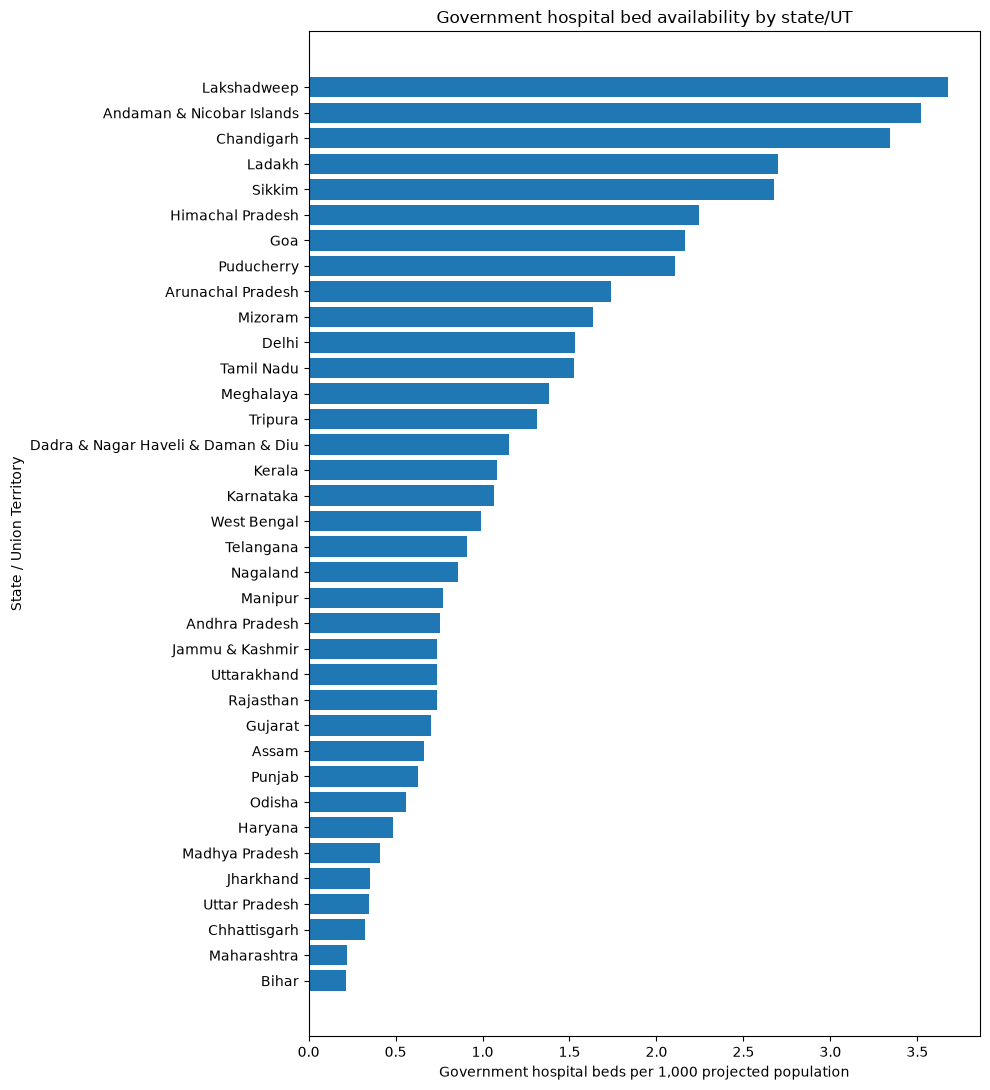

In [3]:
fig, ax = plt.subplots(figsize=(10, 11))
plot_data = ranked.sort_values('beds_per_1000_population', ascending=True)
ax.barh(plot_data['state_ut'], plot_data['beds_per_1000_population'])
ax.set_xlabel('Government hospital beds per 1,000 projected population')
ax.set_ylabel('State / Union Territory')
ax.set_title('Government hospital bed availability by state/UT')
fig.tight_layout()
fig.savefig('../Visualisations/10_government_hospital_beds_per_1000.svg', format='svg', bbox_inches='tight')
plt.show()

## 2. Data limitations

- The bed-count table is dated 31 December 2022; population is projected as of 1 March 2021. The 21-month gap means the denominator is not contemporaneous.
- The rate covers government hospital beds only; it is not total public-plus-private bed availability.
- The 36 published state/UT bed rows sum to 880,307, while the NHP India aggregate row reports 840,455 (a 39,852 difference, equal to the Andhra Pradesh row). This source-table inconsistency is disclosed; the notebook does not calculate a national aggregate rate from the inconsistent totals.
- State reporting and facility coverage may differ. NHP notes that government hospitals include central, state and local government bodies.
- The ratio is a descriptive capacity indicator, not a measure of geographic accessibility, occupancy, staffing, quality or effective service availability.
- Small UTs may have volatile rates because their populations are small.

In [4]:
# Reproducibility checks
assert len(beds) == 36
assert beds['state_ut'].is_unique
assert beds['beds_total_nhp2023'].gt(0).all()
assert beds['population_2021_projected_thousands'].gt(0).all()
assert beds['beds_per_1000_population'].between(0, 10).all()
assert beds['rate_difference'].abs().max() < 0.00011
print('Notebook 08 checks passed.')

Notebook 08 checks passed.
